# Prognos av trafikträngsel 60 minuter fram

**Data:** NordCauc Urban Mobility Intelligence 2023–2025 (Kaggle), filen `traffic_flow_sensors.csv`. Mätningar från trafiksensorer i nordiska städer och Baku.

**Problem:** Kan vi förutsäga trängselnivån vid en sensor **60 minuter framåt i tiden**?

| Nivå | Betydelse |
|---|---|
| free_flow | fritt flöde |
| light | lätt trängsel |
| moderate | måttlig trängsel |
| heavy | kraftig trängsel / kö |

**Varför:** En trafikledare eller pendlare vill veta hur det *blir*, inte bara hur det *är*. En människa kan redan gissa ganska bra: "om en timme är det som nu". Målet är att undersöka om maskininlärning kan göra en bättre gissning än människan, och hur valet av algoritm och optimeringar påverkar resultatet.

## Beslutslogg
Här dokumenterar vi besluten under arbetets gång och varför de togs.

| # | Beslut | Varför |
|---|---|---|
| 1 | Valde datasetet NordCauc Urban Mobility | Nytt dataset för gruppen, många rader, enkelt att få ut vettig data?|
| 2 | Först: förutsäga trängsel *nu* | Enkelt första problem |
| 3 | Ändrade till: förutsäga trängsel *om 60 minuter* | Trängseln *nu* gick nästan att läsa av direkt från hastighet och beläggning. |

**Varför**
om vi gissar traffiken kl.8 med hjälp av hastigheten kl.8 hastighet avslöjar svaret då congestion level verkar vara byggd av den och då vet vi svaret utan att modellen lärt sig ngt. 

free flow och heavy har olika hastigheter därav vet vi congestion level, aja nu förstår jag varför du gjorde future congestion level. Detta kallas data leakage

In [1]:
import os
import kagglehub
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

C:\Users\akobr\mu25-ml-group-2\.pixi\envs\default\lib\python\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = kagglehub.dataset_download("olaflundstrom/nordcauc-urban-mobility-intelligence")
print(os.listdir(path))

['micromobility_trips.csv', 'pedestrian_flow_counters.csv', 'public_transit_ridership.csv', 'traffic_flow_sensors.csv']


In [3]:
df = pd.read_csv(os.path.join(path, 'traffic_flow_sensors.csv'))
df.shape

(200000, 30)

### Datakvalitet

Kolumnen `data_quality_flag` visar om en mätning är pålitlig: good (184 025), sensor_fault (9 928) eller missing_partial (6 047). 

Vi behåller bara `good`, eftersom en trasig sensor ger siffror som inte går att lita på.

In [4]:
df['data_quality_flag'].value_counts()

data_quality_flag
good               184025
sensor_fault         9928
missing_partial      6047
Name: count, dtype: int64

In [5]:
df = df[df['data_quality_flag'] == 'good']

In [6]:
len(df)

184025

### Målet: trafiken 60 minuter fram

**Problem:** Vi vill förutsäga trafikklassen (free_flow, light, moderate, heavy) 60 minuter framåt, utifrån vad vi vet nu.

**Hur:** För varje mätning hämtar vi trafikklassen från samma sensors nästa mätning (`groupby('sensor_id')` och `shift(-1)`), och behåller bara rader där nästa mätning är exakt 60 minuter senare. Kolumnen heter `future_congestion_level`. Kvar blir 1901 av 200 000 rader (ca 1 %), eftersom få sensorer har en mätning exakt en timme senare.

In [7]:
df = df.sort_values(by=['sensor_id', 'timestamp'])
df['future_congestion_level'] = df.groupby('sensor_id')['congestion_level'].shift(-1)
df['next_timestamp'] = df.groupby('sensor_id')['timestamp'].shift(-1)
df['duration_to_next'] = pd.to_datetime(df['next_timestamp']) - pd.to_datetime(df['timestamp'])

df = df[df['duration_to_next'].dt.total_seconds() / 60 == 60]
df = df.drop(columns=['next_timestamp', 'duration_to_next'])


In [8]:
numeric_cols = df.select_dtypes(include='number').columns

scaler = MinMaxScaler()
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

In [9]:
df.head()

,sensor_id,city,country,district,timestamp,date,hour,day_of_week,is_weekend,is_public_holiday,...,truck_count_15min,temperature_c,precipitation_mm,weather_condition,incident_type,ai_predicted_volume,ai_predicted_congestion,ai_model_version,data_quality_flag,future_congestion_level
165398,BAK-BIN-0133,Baku,Azerbaijan,Binagadi,2023-08-18 07:30:00,2023-08-18,0.304348,Friday,False,False,...,0.144578,0.779956,0.000000,clear,none,0.156379,light,CityPulse-XGB,good,heavy
165477,BAK-BIN-0133,Baku,Azerbaijan,Binagadi,2023-10-08 12:15:00,2023-10-08,0.521739,Sunday,True,False,...,0.325301,0.509804,0.009615,drizzle,none,0.329592,heavy,CityPulse-XGB,good,heavy
165495,BAK-BIN-0133,Baku,Azerbaijan,Binagadi,2023-10-24 17:45:00,2023-10-24,0.739130,Tuesday,False,False,...,0.361446,0.396514,0.019231,light_rain,none,0.367377,heavy,CityPulse-XGB,good,heavy
165711,BAK-BIN-0133,Baku,Azerbaijan,Binagadi,2024-05-16 07:45:00,2024-05-16,0.304348,Thursday,False,False,...,0.144578,0.921569,0.086538,drizzle,none,0.144407,light,CityPulse-XGB,good,heavy
165829,BAK-BIN-0133,Baku,Azerbaijan,Binagadi,2024-08-17 01:15:00,2024-08-17,0.043478,Saturday,True,False,...,0.397590,0.779956,0.028846,light_rain,none,0.204639,moderate,CityPulse-XGB,good,light


In [10]:
df['future_congestion_level'].value_counts(normalize=True)

future_congestion_level
free_flow    0.472383
moderate     0.186218
light        0.178327
heavy        0.163072
Name: proportion, dtype: float64

### Tar bort orelevanta kolumner

Datasetet har 30 kolumner. Vi behåller 17 som beskriver trafiksituationen nu (tid på dygnet, vägtyp, trafikmått, väder, incidenter), samt målet `future_congestion_level`.

**Vi tar bort:** identifierare och plats (sensor_id, city, country, district, latitude, longitude), exakt tidpunkt (timestamp, date), färdiga AI-prognoser (ai_predicted_volume, ai_predicted_congestion, ai_model_version) och data_quality_flag. Gruppen valde också att inte ta med ev_count_15min (antal elbilar)

**Varför:** en modell som ska gälla för alla sensorer ska vara **Generisk** ska inte lära sig utantill vilken sensor eller stad en rad kommer från, och de färdiga prognoserna är någon annans gissning som skulle dölja vad vår egen modell lär sig.

Nuvarande trafikklass (`congestion_level`) och hastighet behålls, eftersom vi känner till dem när vi gissar 60 minuter fram.

In [11]:
kolumner = [
    'hour', 'day_of_week', 'is_weekend', 'is_public_holiday', 'season',
    'road_type', 'speed_limit_kmh', 'lane_count', 'vehicle_count_15min',
    'avg_speed_kmh', 'congestion_level', 'occupancy_rate', 'truck_count_15min',
    'temperature_c', 'precipitation_mm', 'weather_condition', 'incident_type', 'future_congestion_level'
]



In [12]:
df = df[kolumner].dropna()

In [13]:
df.isna().sum().sum()

np.int64(0)

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.info()

<class 'pandas.DataFrame'>
Index: 1901 entries, 165398 to 11130
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   hour                     1901 non-null   float64
 1   day_of_week              1901 non-null   str    
 2   is_weekend               1901 non-null   bool   
 3   is_public_holiday        1901 non-null   bool   
 4   season                   1901 non-null   str    
 5   road_type                1901 non-null   str    
 6   speed_limit_kmh          1901 non-null   float64
 7   lane_count               1901 non-null   float64
 8   vehicle_count_15min      1901 non-null   float64
 9   avg_speed_kmh            1901 non-null   float64
 10  congestion_level         1901 non-null   str    
 11  occupancy_rate           1901 non-null   float64
 12  truck_count_15min        1901 non-null   float64
 13  temperature_c            1901 non-null   float64
 14  precipitation_mm         1901 non-

In [16]:
df.describe()

,hour,speed_limit_kmh,lane_count,vehicle_count_15min,avg_speed_kmh,occupancy_rate,truck_count_15min,temperature_c,precipitation_mm
count,1901.000000,1901.000000,1901.000000,1901.000000,1901.000000,1901.000000,1901.000000,1901.000000,1901.000000
mean,0.495552,0.346134,0.407680,0.096181,0.376863,0.328172,0.113504,0.500484,0.049640
std,0.296736,0.225487,0.244059,0.120979,0.182574,0.294025,0.138500,0.271075,0.113011
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.260870,0.200000,0.250000,0.018685,0.246400,0.058036,0.024096,0.278867,0.000000
50%,0.478261,0.300000,0.250000,0.056054,0.347200,0.306548,0.072289,0.492375,0.000000
75%,0.739130,0.500000,0.500000,0.115845,0.486400,0.523810,0.144578,0.762527,0.048077
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [17]:
len(df)

1901

### Antal fordon per 15 minuter

**Fråga:** Hur är antalet fordon (vehicle_count_15min) fördelat?

**Varför:** Vi vill lära känna datan och kontrollera att den ser rimlig ut innan vi tränar en modell.

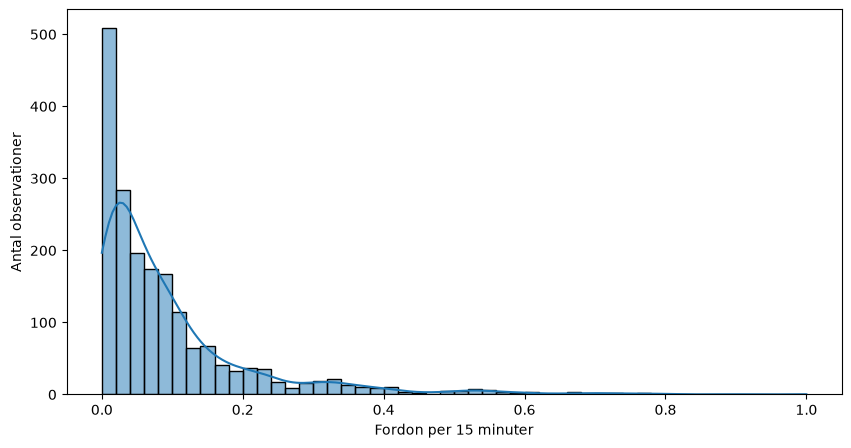

In [18]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df,x="vehicle_count_15min",bins=50,kde=True)

plt.xlabel("Fordon per 15 minuter")
plt.ylabel("Antal observationer")

plt.show()


**Resultat:** De flesta mätningar har få fordon, och några få har mycket högre värden. Fördelningen är alltså skev åt höger. Därför är medianen en bättre bild av ett typiskt värde än medelvärdet, som dras upp av de extrema värdena.

### Fördelning av målvariabeln

**Fråga**: Är de fyra trafikklasserna (free_flow, light, moderate, heavy) jämnt fördelade, eller är någon klass mycket vanligare?

**Varför:** Om en klass dominerar kan en modell få hög accuracy genom att alltid gissa den klassen. Då behöver vi veta vad en enkel gissning ger för att kunna bedöma om modellen faktiskt lär sig något.

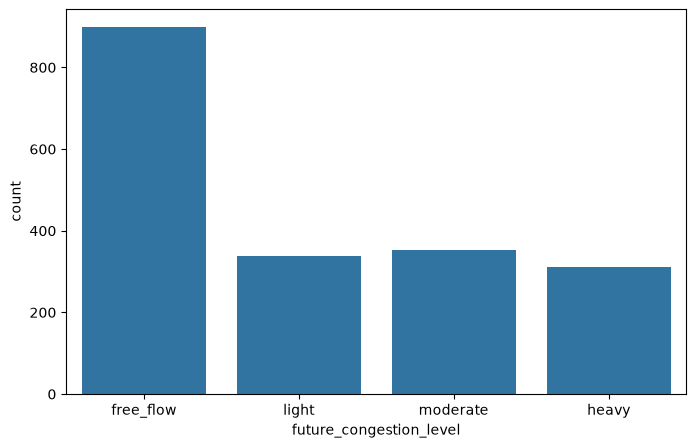

In [19]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='future_congestion_level', order=['free_flow', 'light', 'moderate', 'heavy'])
plt.show()

In [20]:
df['future_congestion_level'].value_counts(normalize=True)

future_congestion_level
free_flow    0.472383
moderate     0.186218
light        0.178327
heavy        0.163072
Name: proportion, dtype: float64

### Resultat

free_flow är vanligast (47,2 %) och heavy minst (16,3 %).

Att alltid gissa free_flow ger alltså 47,2 % rätt, och det är vår baslinje.

En modell måste slå 47,2 % på testdatan för att visa att den har lärt sig något.

### Trafikbelastning per timme

**Fråga:** Varierar trafikklassen 60 minuter fram (future_congestion_level) beroende på tid på dygnet?

**Varför:** Timmen är känd i förväg, så den kan användas för att förutsäga framtida trafik. Om heavy är vanligare vid vissa timmar (t.ex. rusningstid) separerar hour klasserna och är en användbar feature.

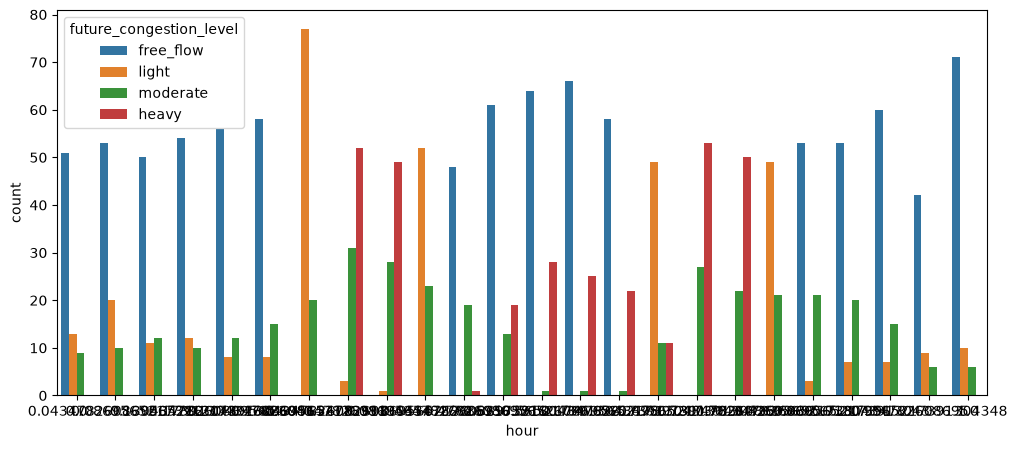

In [21]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='hour', hue='future_congestion_level', hue_order=['free_flow', 'light', 'moderate', 'heavy'])
plt.show()

**Resultat:** Heavy är vanligast kl. 7-8 och 16-17, en timme före själva rusningstiden, eftersom `hour` är klockslaget för mätningen men trafikklassen gäller 60 minuter senare. 

Light är vanligast strax före och efter topparna (kl. 6, 9, 15 och 18). Free_flow är vanligast nattetid (0-5), mitt på dagen (10-14) och sent på kvällen (19-23). 

Klasserna fördelas alltså tydligt olika över dygnet, så `hour` separerar klasserna väl. Det gör `hour` till en användbar feature, och eftersom timmen är känd i förväg kan den användas för att förutsäga framtida trafik.

### Trafikbelastning per väder

**Fråga:** Påverkar vädret (weather_condition) vilken trafikklass vi får?

**Varför:** Väder är något vi kan känna till i förväg (t.ex. via väderprognos), så det kan användas för att förutsäga framtida trafik. Om fördelningen av trafikklasser skiljer sig mellan väderförhållanden separerar vädret klasserna och är en användbar feature.

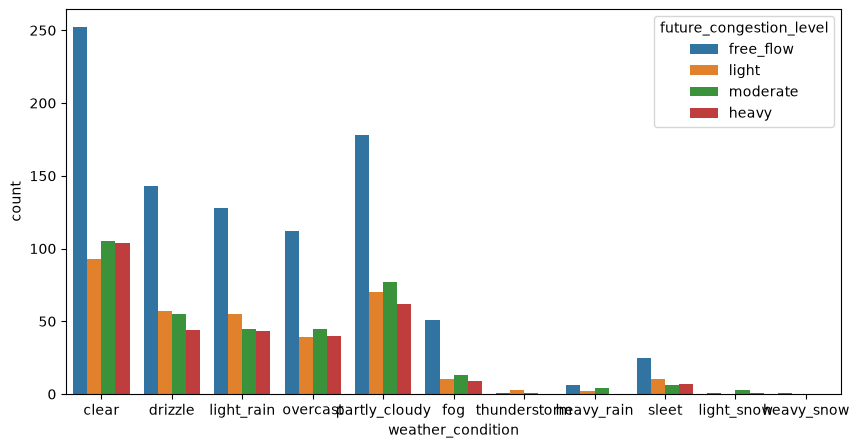

In [22]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='weather_condition', hue='future_congestion_level', hue_order=['free_flow', 'light', 'moderate', 'heavy'])
plt.show()

In [23]:
df.groupby('weather_condition')['future_congestion_level'].value_counts(normalize=True)

weather_condition  future_congestion_level
clear              free_flow                  0.454874
                   moderate                   0.189531
                   heavy                      0.187726
                   light                      0.167870
drizzle            free_flow                  0.478261
                   light                      0.190635
                   moderate                   0.183946
                   heavy                      0.147157
fog                free_flow                  0.614458
                   moderate                   0.156627
                   light                      0.120482
                   heavy                      0.108434
heavy_rain         free_flow                  0.500000
                   moderate                   0.333333
                   light                      0.166667
heavy_snow         free_flow                  1.000000
light_rain         free_flow                  0.472325
                   lig

In [24]:
df['weather_condition'].value_counts()

weather_condition
clear            554
partly_cloudy    387
drizzle          299
light_rain       271
overcast         236
fog               83
sleet             48
heavy_rain        12
thunderstorm       5
light_snow         5
heavy_snow         1
Name: count, dtype: int64

**Resultat:** De flesta väder har ungefär samma fördelning som totalen (ca 47 % free_flow). Fog har lite fler free_flow (61 %). 

Väder med få rader (heavy_snow, thunderstorm, light_snow) ger extrema procenttal som inte går att lita på. Vädret separerar klasserna svagare än `hour` och är en möjlig men inte avgörande feature. Vi behåller den och testar i modellen om den hjälper.

### Samband mellan siffer-kolumner

**Fråga:** Hur hänger siffer-kolumnerna ihop med varandra?

**Varför:** Kolumner som säger nästan samma sak behövs inte båda två. Vi vill också hitta kolumner som avslöjar svaret, så att vi inte använder dem.

<Axes: >

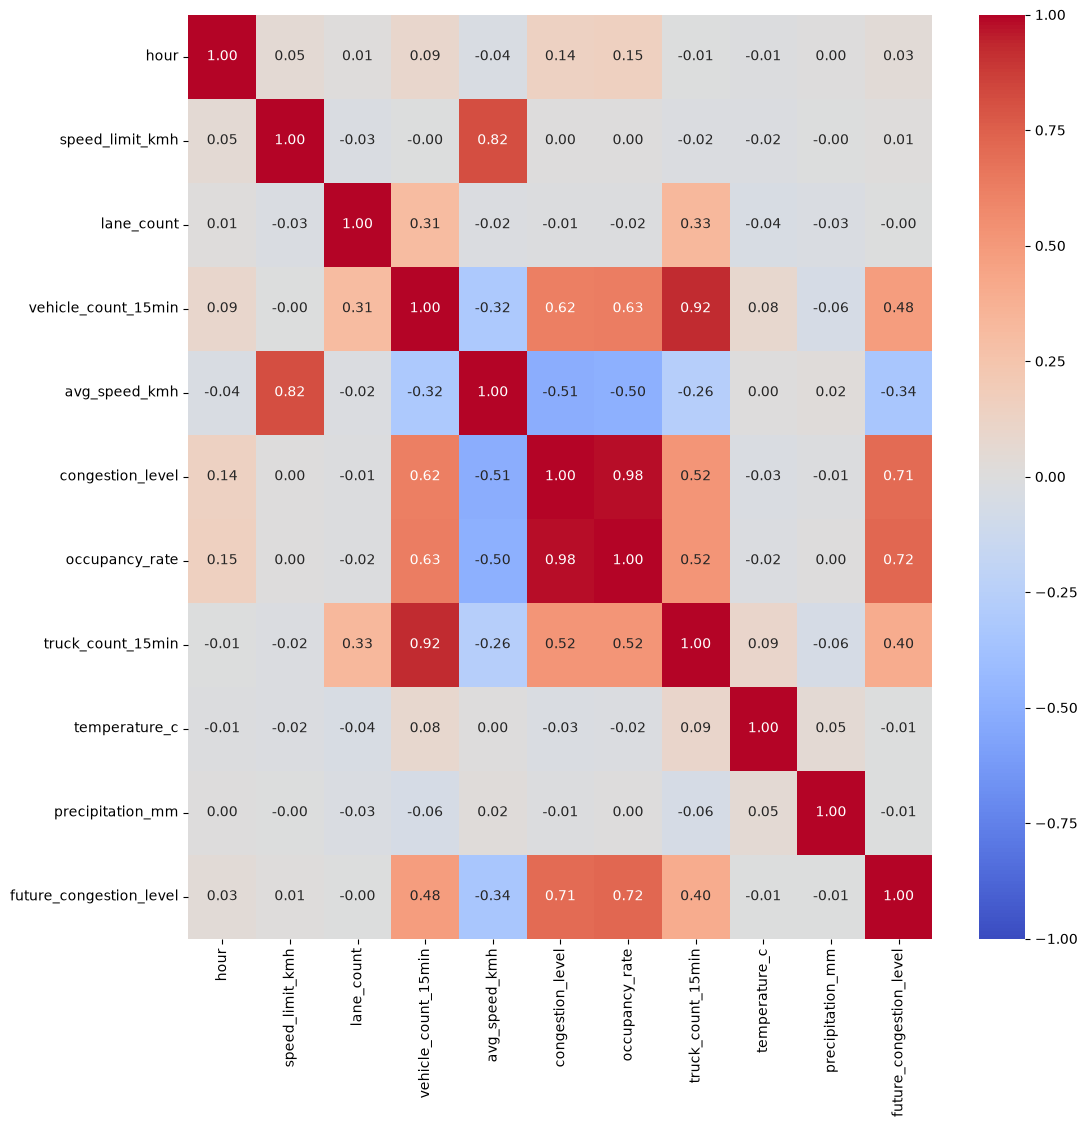

In [25]:
df_clean = df.dropna()

df_clean["future_congestion_level"] = df_clean["future_congestion_level"].map({"free_flow": 0, "light": 1, "moderate": 2, "heavy": 3})
df_clean["congestion_level"] = df_clean["congestion_level"].map({"free_flow": 0, "light": 1, "moderate": 2, "heavy": 3})

numeric_df = df_clean.select_dtypes(include=['float64','int64', 'int8'])
corr_matrix = numeric_df.corr()
plt.figure(figsize=(12,12))
sns.heatmap(corr_matrix, annot=True, vmin=-1, vmax=1, cmap='coolwarm', fmt='.2f')
#plt.savefig('correlation.png')

**Resultat:** 

### future_congestion_level 
har någon slags correlation med vehicle_count_15min, avg_speed_kmh, congestion_level och truck_count 

Två par hänger starkt ihop: truck_count_15min och vehicle_count_15min (0,92) samt speed_limit_kmh och avg_speed_kmh (0,82).

Det är logiskt: fler fordon ger fler lastbilar, och vägar med högre hastighetsgräns har högre medelhastighet. Kolumnerna i varje par säger nästan samma sak. Temperatur och nederbörd hänger inte ihop med något (nära 0). Målet är text och syns inte i heatmapen, så det undersöker vi i nästa steg.

### Medelhastighet per trafikklass

**Fråga:** Skiljer sig avg_speed_kmh mellan trafikklasserna 60 minuter fram?

**Varför:** Heatmapen visar bara hur siffer-kolumner hänger ihop med varandra. Målet är text och syns inte där. Därför jämför vi medelvärdet per klass: om det skiljer sig mellan klasserna kan kolumnen hjälpa modellen.

In [26]:
df.groupby('future_congestion_level')['avg_speed_kmh'].mean()

future_congestion_level
free_flow    0.440075
heavy        0.281174
light        0.349996
moderate     0.326034
Name: avg_speed_kmh, dtype: float64

**Resultat:** free_flow (61 km/h) och heavy (41 km/h) skiljer sig tydligt i medelhastighet, light (50) och moderate (47) knappt. Hastigheten är en användbar feature, främst för att skilja free_flow från heavy.

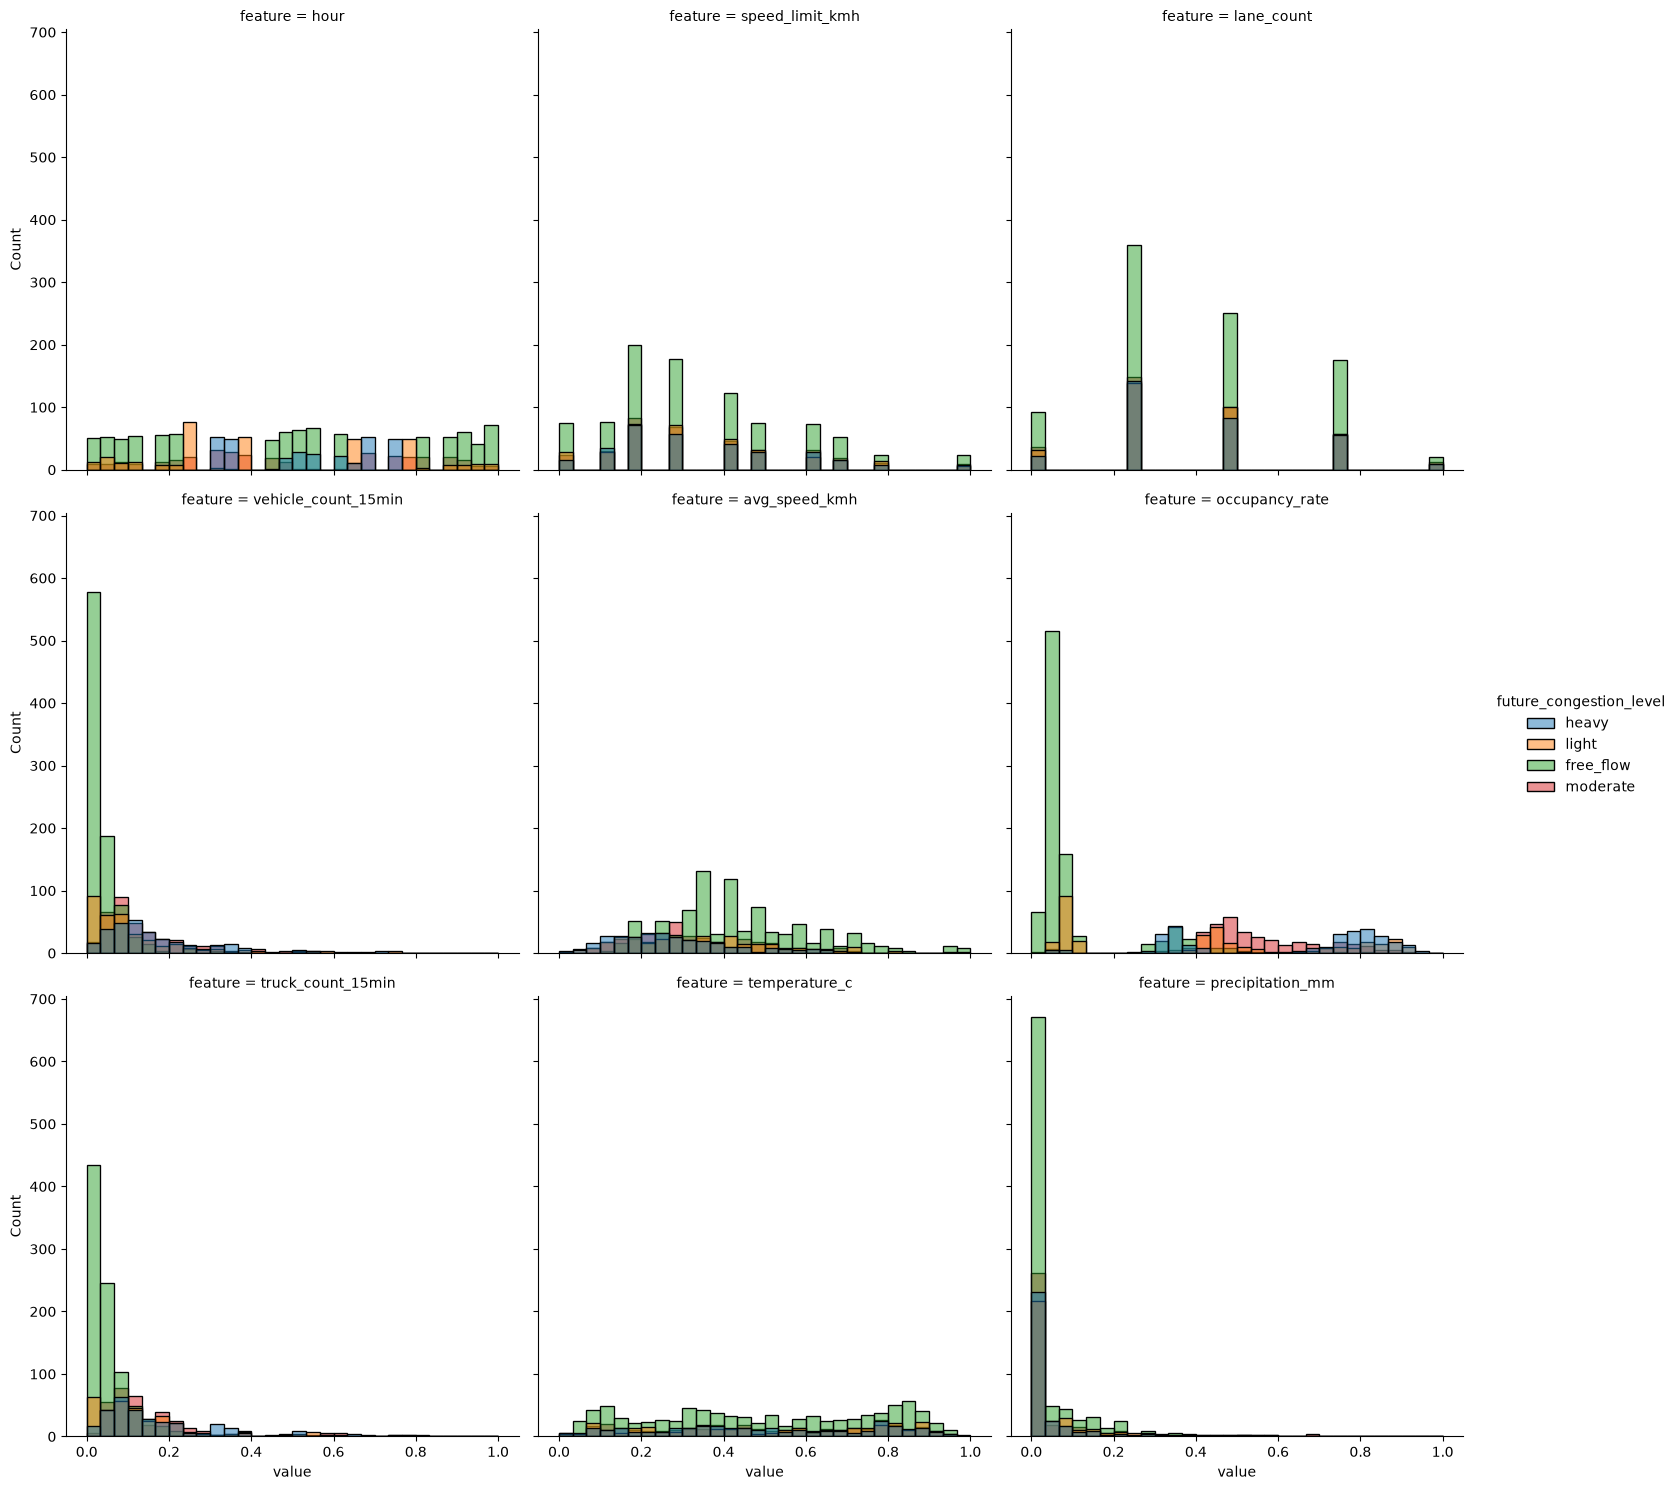

In [27]:
columns_to_drop = df.select_dtypes(include=['string', 'bool']).columns.difference(['future_congestion_level'])
long_df = df.drop(columns=columns_to_drop).melt(id_vars="future_congestion_level", var_name="feature", value_name="value")
sns.displot(data=long_df, x="value", col="feature", hue="future_congestion_level", col_wrap=3)


# Det vi har visat

**Målet:** trafikklassen 60 minuter fram (`future_congestion_level`). Free_flow är vanligast (47,2 %), så baslinjen att slå är 47,2 %.

**Timme:** heavy toppar kl. 7-8 och 16-17, så `hour` separerar klasserna tydligt.

**Väder:** de flesta väder liknar totalen, så vädret är en svagare feature. Men för **light_snow** så stack en viss kategori av trafikflöde ut ("moderate" traffikstockning). 

**Samband:** truck_count och vehicle_count (0,92) samt speed_limit och avg_speed (0,82) säger nästan samma sak.

**Hastighet:** free_flow (61 km/h) och heavy (41 km/h) skiljer sig tydligt, så hastigheten är en användbar feature.

# Del 2

## Klassificering

In [28]:
x = df.drop(columns=['future_congestion_level'])
y = df['future_congestion_level']

In [29]:
x.shape, y.shape

((1901, 17), (1901,))

In [30]:
x = pd.get_dummies(x, drop_first=True)

In [31]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

### Baslinje

**Fråga:** Hur bra är en modell som alltid gissar den vanligaste klassen?

**Varför:** Det är den enklaste gissningen och blir måttstocken. En riktig modell måste slå den för att ha lärt sig något.

In [32]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(x_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](4,)","[0.47,0.16,0.18,0.19]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[object](4,)","['free_flow','heavy','light','moderate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](43,)","['hour','is_weekend','is_public_holiday',..., 'incident_type_parking_violation','incident_type_pedestrian_crossing', 'incident_type_road_works']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,4
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,43
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [33]:
y_pred = baseline.predict(x_test)
accuracy_score(y_test, y_pred)

0.47244094488188976

**Resultat:** DummyClassifier, som alltid gissar free_flow, ger en accuracy på 47,2 % på testdatan. 
Det är siffran våra modeller måste slå.

## Baslinje 2: människans gissning
**Fråga:** Hur ofta har man rätt om man gissar att trafiken om en timme blir som nu?

**Varför:** Det är så en pendlare eller trafikledare skulle gissa utan maskininlärning. Uppgiften säger att ML ska göra en bättre "chansning" än en människa, så det är den här baslinjen som verkligen räknas.

In [34]:
human_guess = df.loc[x_test.index, 'congestion_level']
acc_human = accuracy_score(y_test, human_guess)
acc_human

0.6115485564304461

**Resultat:** 61%

### Beslutsträd

**Fråga:** Kan ett beslutsträd gissa trafikklassen 60 minuter fram bättre än baslinjen?

**Varför:** Ett träd ställer ja/nej-frågor om features (till exempel "är hastigheten under 50?") och hittar själv vilka som är viktiga. Det är en enkel modell att börja med och går att förklara.

In [35]:
#x = df_processed.drop(columns=["future_congestion_level"])
cols = ['hour', 'is_weekend', 'avg_speed_kmh', 'vehicle_count_15min', 'occupancy_rate', 'precipitation_mm']
x = df[cols]
x['is_light_snow'] = (df['weather_condition'] == 'light_snow')

y = df["future_congestion_level"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

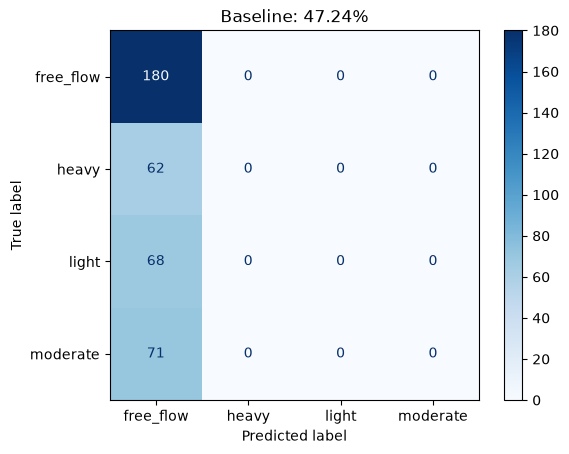

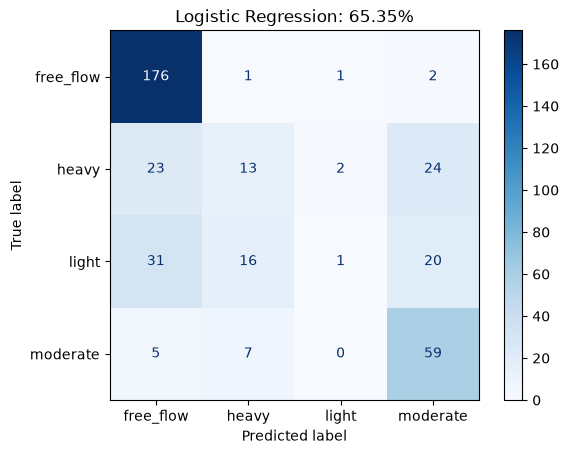

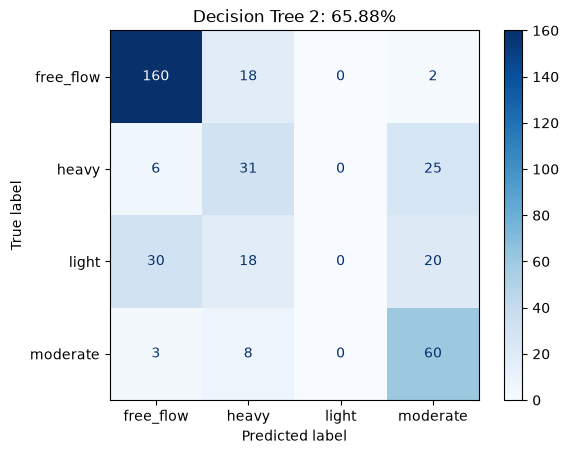

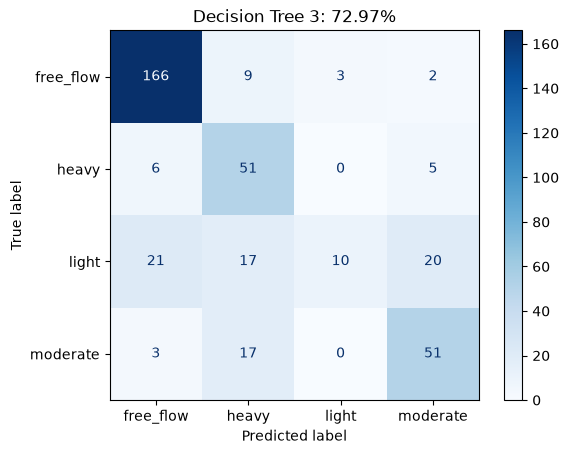

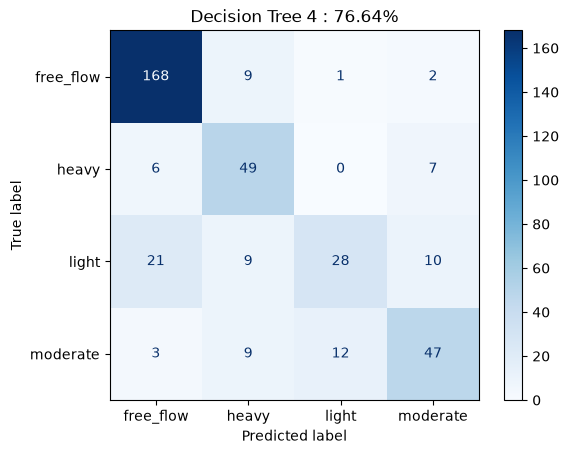

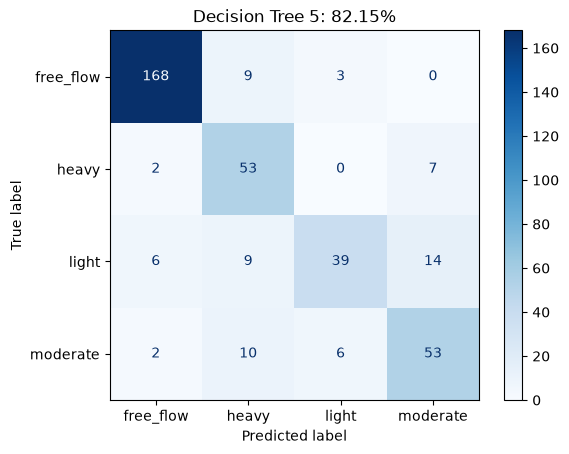

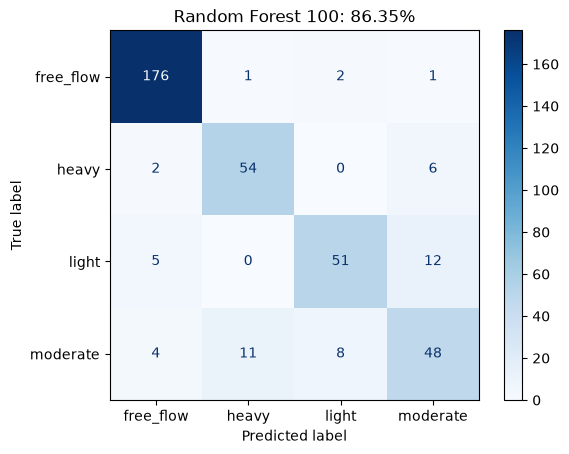

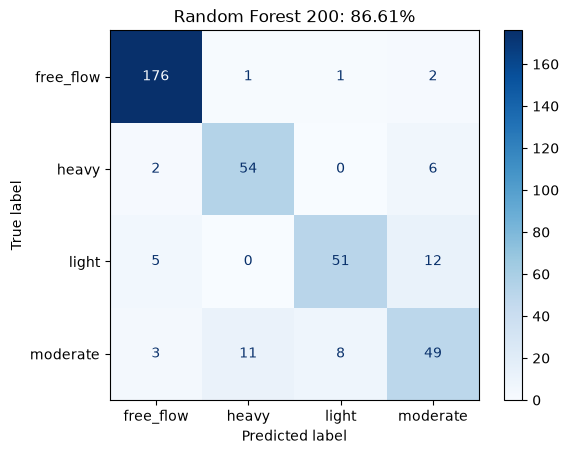

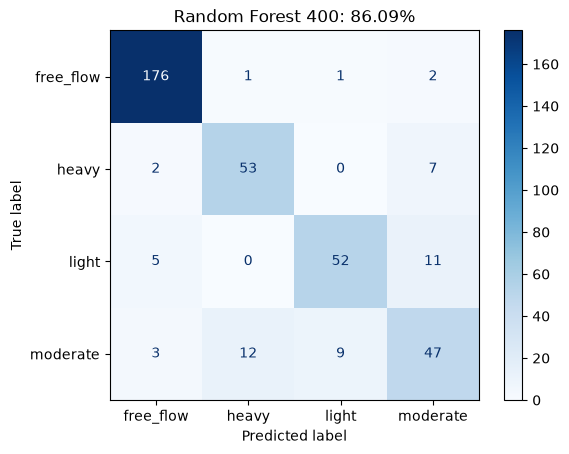

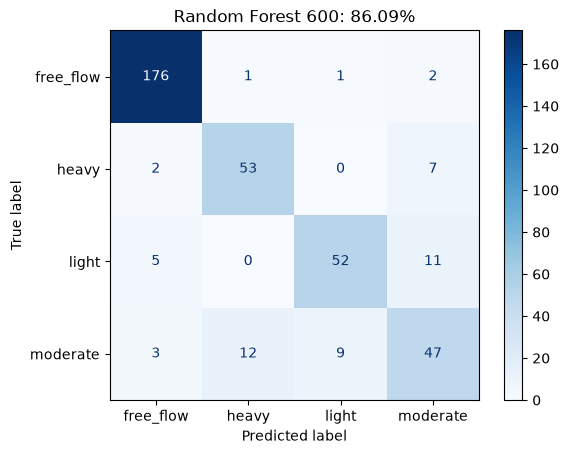

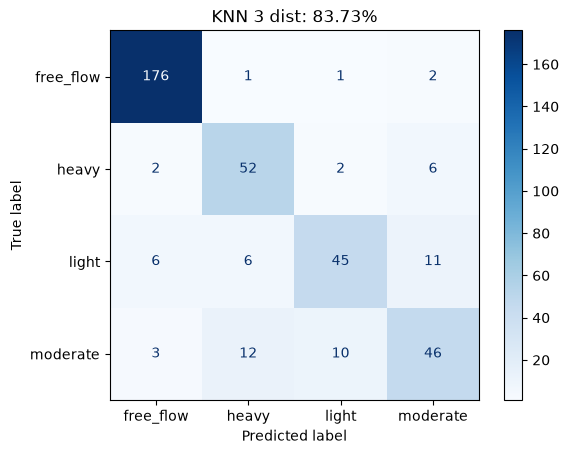

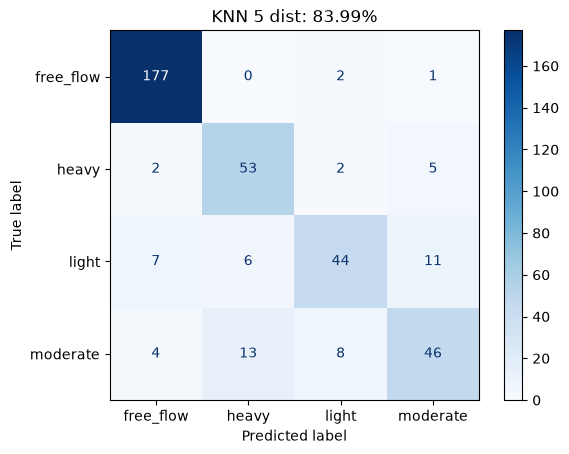

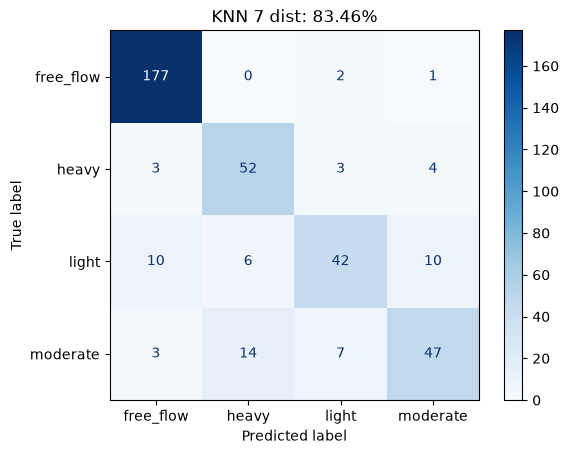

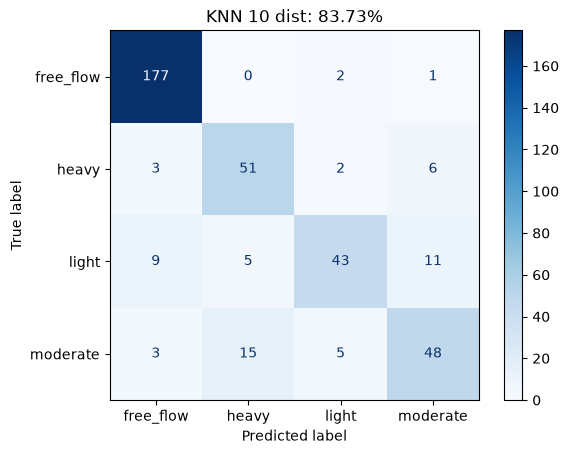

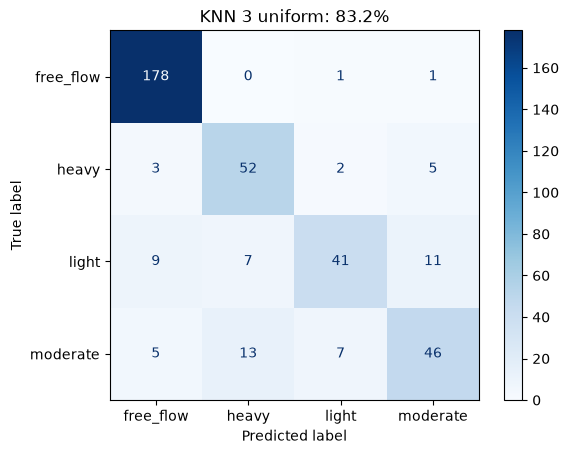

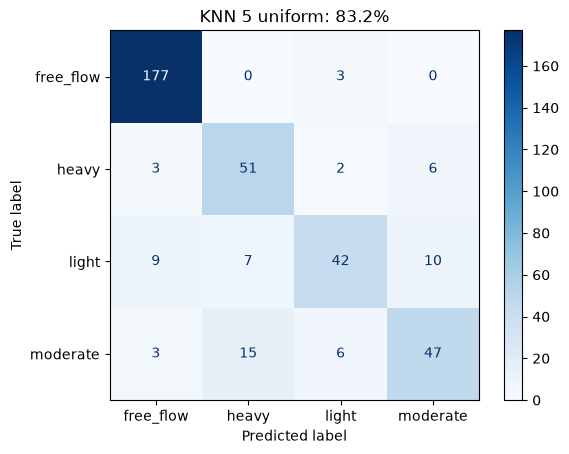

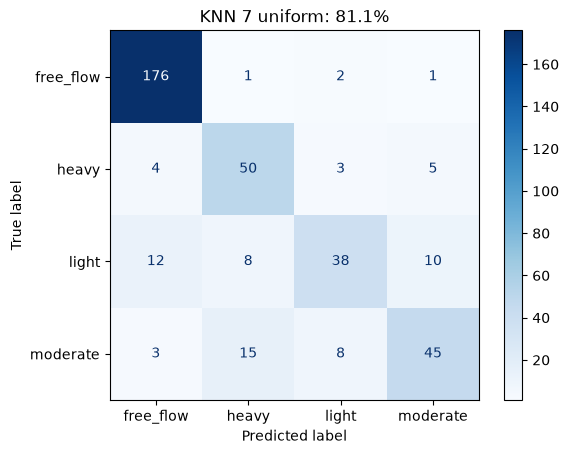

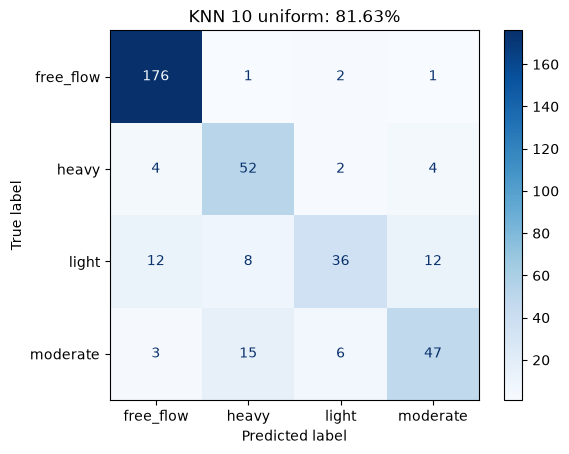

In [36]:
models = {
    'Baseline': DummyClassifier(strategy="most_frequent").fit(x_train, y_train),
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Decision Tree 2': DecisionTreeClassifier(max_depth=2, random_state=42),
    'Decision Tree 3': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Decision Tree 4 ': DecisionTreeClassifier(max_depth=4, random_state=42),
    'Decision Tree 5': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest 100': RandomForestClassifier(n_estimators=100,random_state=42),
    'Random Forest 200': RandomForestClassifier(n_estimators=200,random_state=42),
    'Random Forest 400': RandomForestClassifier(n_estimators=400,random_state=42),
    'Random Forest 600': RandomForestClassifier(n_estimators=600,random_state=42),
    'KNN 3 dist': KNeighborsClassifier(n_neighbors=3,weights='distance'),
    'KNN 5 dist': KNeighborsClassifier(n_neighbors=5,weights='distance'),
    'KNN 7 dist': KNeighborsClassifier(n_neighbors=7,weights='distance'),
    'KNN 10 dist': KNeighborsClassifier(n_neighbors=10,weights='distance'),
    'KNN 3 uniform': KNeighborsClassifier(n_neighbors=3,weights='uniform'),
    'KNN 5 uniform': KNeighborsClassifier(n_neighbors=5,weights='uniform'),
    'KNN 7 uniform': KNeighborsClassifier(n_neighbors=7,weights='uniform'),
    'KNN 10 uniform': KNeighborsClassifier(n_neighbors=10,weights='uniform'),
}

for name, model in models.items():
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)

    ConfusionMatrixDisplay.from_estimator(model, x_test, y_test,cmap='Blues')

    plt.title(f'{name}: {round(accuracy_score(y_test, y_pred) * 100, 2)}%')
    plt.show()

**Resultat:** Beslutsträdet (random_state=42) ger en accuracy på 80,6 % på testdatan, mot baslinjens 47,2 %. Modellen har alltså lärt sig något användbart.

### Confusion matrix

**Fråga:** Vilka trafikklasser gissar trädet rätt på, och vilka blandar det ihop?

**Varför:** Accuracy säger bara hur ofta modellen har rätt totalt. Confusion matrix visar var den har fel, och det är det vi behöver för att veta vad vi ska förbättra.

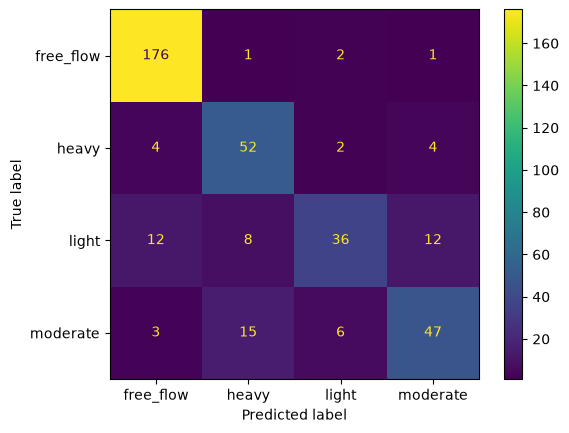

In [37]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

**Resultat:** Trädet gissar free_flow bäst (159 av 180 rätt). Flest förväxlingar är mellan light och moderate (14 + 9 = 23 fall) och mellan heavy och moderate (11 + 10 = 21). Heavy och light blandas aldrig ihop (0 fall), vilket är logiskt eftersom de ligger längst ifrån varandra. Svårigheten med light och moderate stämmer med dataanalysen, där medelhastigheten var nästan lika (50 och 47 km/h).

### Precision, recall och F1

**Fråga:** Hur bra gissar trädet varje enskild trafikklass?

**Varför:** Accuracy visar bara hur ofta modellen har rätt totalt. F1-score säger hur bra den är på varje klass, och passar bättre när klasserna är olika stora (free_flow är mycket vanligare än de andra).

In [38]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

   free_flow       0.90      0.98      0.94       180
       heavy       0.68      0.84      0.75        62
       light       0.78      0.53      0.63        68
    moderate       0.73      0.66      0.70        71

    accuracy                           0.82       381
   macro avg       0.78      0.75      0.76       381
weighted avg       0.81      0.82      0.81       381



**Resultat:** Trädet har bäst F1-score för free_flow (0,91), sedan heavy (0,80), light (0,70) och moderate (0,67). 
Heavy går bra eftersom klassen har tydligt lägre medelhastighet (41 km/h mot 47-50 för light och moderate), så trädet känner lätt igen den. 

Light och moderate är svårast, eftersom hastigheten är nästan lika för dem. Accuracy är 0,81 (baslinjen 0,47).

# Det vi har visat klassificiering

**Slutsats**

**Slog vi människan**? Ja. Vi skapade modeller med olika klassifierare, den bästa var random forest med 200 estimatorer. den fick accuracy 86,61% vilket slår båda våra baselines.

**Bästa algoritmen**:
Random forest. Trafiken har toppar under dygnet och tydliga gränser, till exempel rusningstid och låg hastighet, och sådana samband fångar beslutsträd bättre än logistisk regression, som bara ser raka samband. Random forest låter dessutom 200 träd rösta, vilket gör gissningarna stabilare än ett ensamt träd.

**Optimeringarna**:  
**Begränsningar**: bara ca 1 % av de 200 000 raderna hade en mätning exakt 60 minuter senare, så vi har lite data och få testrader.